# Bloc 4 — Graphes et processus (cours 4)
**Fichiers (Health, partie clinique)** : `clinical_encounters`, `clinical_procedures`, `patient_administration` (versions `_cleaned`).

Plan :
1. **Définir** les graphes : nœuds, liens, orientation, poids.
2. **Décrire** chaque graphe : n, m, densité, distribution des degrés, loi de puissance.
3. **Nœuds importants** : degré, closeness, betweenness ; plus courts chemins.
4. **Communautés** : composantes connexes, coefficient de regroupement, Louvain, Girvan-Newman, Infomap, avec la modularité Q.
5. **Process mining** : les consultations forment un vrai *event log* (un patient = un cas, un type de consultation = une activité, un horodatage). On construit le graphe des successions directes (DFG) et on applique Heuristic et Inductive Miner (`pm4py`).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import networkx as nx
from networkx.algorithms import bipartite
from networkx.algorithms import community as nxc

sns.set_style('white')
chemin = 'cleaned/'
enc = pd.read_csv(chemin + 'clinical_encounters_cleaned.csv', parse_dates=['encounter_start', 'encounter_end'])
proc = pd.read_csv(chemin + 'clinical_procedures_cleaned.csv', parse_dates=['scheduled_time', 'performed_time'])
pat = pd.read_csv(chemin + 'patient_administration_cleaned.csv')

# groupes de patients définis aux blocs 2-3 (procédure MRP-42), réutilisés pour colorer les graphes
mrp = proc[proc.procedure_code == 'MRP-42']
elite = set(mrp[mrp.authorization_class == 'restricted_specialist'].patient_number)   # 8 patients
recherche = set(mrp[mrp.authorization_class == 'research_restricted'].patient_number)  # 20 patients
def groupe(n):
    return 'MRP-42 specialist' if n in elite else 'MRP-42 recherche' if n in recherche else 'autre'
print(len(elite), 'patients MRP-42 restricted_specialist ;', len(recherche), 'patients MRP-42 research_restricted')

8 patients MRP-42 restricted_specialist ; 20 patients MRP-42 research_restricted


## 1. Définition des graphes
| Graphe | Nœuds | Liens | Orienté ? | Poids |
|---|---|---|---|---|
| **G** (biparti) | 240 patients + 8 professionnels (licences) | le professionnel a reçu le patient en consultation (`attending_license_number`) ou lui a fait une procédure (`performing_license_number`) | non | nombre d'interactions |
| **P** (projection) | 8 professionnels | deux professionnels ont au moins un patient en commun | non | nombre de patients partagés |
| **R** (sous-graphe restreint) | patients et professionnels | même lien que G, mais seulement pour les consultations `restricted` et les procédures à autorisation restreinte | non | nombre d'interactions restreintes |
| **DFG** (processus, section 5) | types de consultation | succession directe de deux consultations chez un même patient | **oui** (A → B) | nombre de successions |

Les établissements (3) ne sont pas des nœuds : avec 3 valeurs ils n'apportent pas de structure de réseau (on les traite au bloc 5).

In [2]:
def graphe_biparti(liens):
    """liens : DataFrame patient_number, lic -> graphe biparti pondéré"""
    w = liens.groupby(['patient_number', 'lic']).size().reset_index(name='weight')
    g = nx.Graph()
    g.add_nodes_from(w.patient_number.unique(), bipartite=0, kind='patient')
    g.add_nodes_from(w.lic.unique(), bipartite=1, kind='professionnel')
    g.add_weighted_edges_from(w[['patient_number', 'lic', 'weight']].itertuples(index=False))
    return g

liens = pd.concat([enc[['patient_number', 'attending_license_number']].rename(columns={'attending_license_number': 'lic'}),
                   proc[['patient_number', 'performing_license_number']].rename(columns={'performing_license_number': 'lic'})])
G = graphe_biparti(liens)

restr_enc = enc[enc.confidentiality_class == 'restricted']
restr_proc = proc[proc.authorization_class.str.contains('restricted')]
liens_r = pd.concat([restr_enc[['patient_number', 'attending_license_number']].rename(columns={'attending_license_number': 'lic'}),
                     restr_proc[['patient_number', 'performing_license_number']].rename(columns={'performing_license_number': 'lic'})])
R = graphe_biparti(liens_r)

pros = [n for n, d in G.nodes(data=True) if d['kind'] == 'professionnel']
P = bipartite.weighted_projected_graph(G, pros)   # poids = nb de patients partagés

## 2. Description des graphes

In [3]:
def decrire(g, nom):
    deg = dict(g.degree())
    return {'graphe': nom, 'n': g.number_of_nodes(), 'm': g.number_of_edges(), 'densité': round(nx.density(g), 4),
            'composantes': nx.number_connected_components(g), 'degré moyen': round(np.mean(list(deg.values())), 2),
            'degré max': max(deg.values())}
pd.DataFrame([decrire(G, 'G biparti'), decrire(P, 'P professionnels'), decrire(R, 'R restreint')])

,graphe,n,m,densité,composantes,degré moyen,degré max
0,G biparti,248,844,0.0276,1,6.81,118
1,P professionnels,8,28,1.0000,1,7.00,7
2,R restreint,116,165,0.0247,1,2.84,39


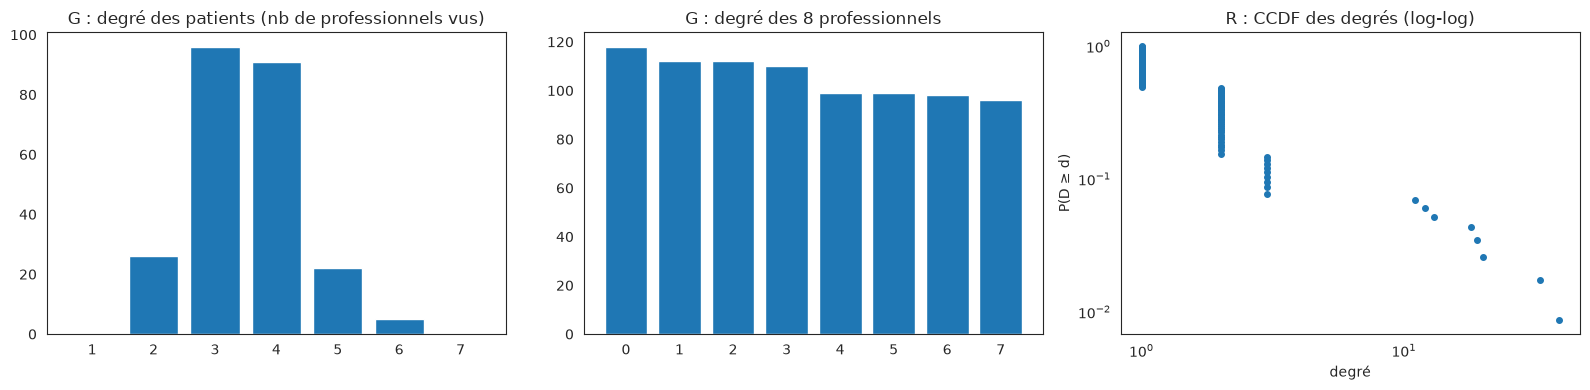

Degré des professionnels dans G : {'LIC-VLN-MED-1001': 118, 'LIC-VLN-RES-1016': 112, 'LIC-VLN-MED-1002': 112, 'LIC-VLN-MED-1006': 110, 'LIC-VLN-RES-1044': 99, 'LIC-VLN-MED-1003': 99, 'LIC-VLN-MED-1004': 98, 'LIC-VLN-MED-1005': 96}


In [4]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
deg_pat = [d for n, d in G.degree() if G.nodes[n]['kind'] == 'patient']
deg_pro = [d for n, d in G.degree() if G.nodes[n]['kind'] == 'professionnel']
axes[0].hist(deg_pat, bins=range(1, 9), align='left', rwidth=.8); axes[0].set_title('G : degré des patients (nb de professionnels vus)')
axes[1].bar(range(len(deg_pro)), sorted(deg_pro, reverse=True)); axes[1].set_title('G : degré des 8 professionnels')
# loi de puissance ? CCDF log-log des degrés de R (le graphe le plus hétérogène)
v = np.sort([d for _, d in R.degree()])
axes[2].loglog(v, 1 - np.arange(len(v)) / len(v), 'o', ms=4)
axes[2].set_title('R : CCDF des degrés (log-log)'); axes[2].set_xlabel('degré'); axes[2].set_ylabel('P(D ≥ d)')
plt.tight_layout(); plt.show()
print('Degré des professionnels dans G :', dict(sorted(dict(G.degree(pros)).items(), key=lambda x: -x[1])))

**Lecture**
- **G** est très peu dense (≈ 0,03) mais connexe : chaque patient voit 2 à 6 des 8 professionnels, et chaque professionnel suit 96 à 118 patients. Les degrés des professionnels sont **homogènes** : dans le graphe complet, aucun praticien n'est central.
- **P** est **complet** (densité 1) : les 8 professionnels partagent tous des patients. La projection n'apporte rien de plus que les poids.
- **Loi de puissance** : non. Dans G, les degrés des patients sont bornés (2 à 6) et ceux des professionnels presque égaux. Dans R, la CCDF n'est pas une droite : quelques professionnels ont beaucoup de liens, et presque tous les patients en ont un seul. C'est une structure **en étoiles** (biparti patients-praticiens), pas un réseau sans échelle.

## 3. Nœuds importants
Dans un graphe pondéré, les fonctions de `networkx` interprètent le poids comme une **distance** pour les plus courts chemins. Nos poids sont des **intensités** (plus d'interactions = plus proche), donc on utilise la distance `1 / poids` pour closeness et betweenness. Le degré pondéré (*strength*) est la somme des poids.

In [5]:
def centralites(g):
    for u, v, d in g.edges(data=True):
        d['distance'] = 1 / d['weight']
    df = pd.DataFrame({'degré': dict(g.degree()),
                       'degré pondéré': dict(g.degree(weight='weight')),
                       'closeness': nx.closeness_centrality(g, distance='distance'),
                       'betweenness': nx.betweenness_centrality(g, weight='distance')})
    df['type'] = [g.nodes[n]['kind'] for n in df.index]
    df['groupe'] = [groupe(n) if g.nodes[n]['kind'] == 'patient' else '' for n in df.index]
    return df.round(3)

cG = centralites(G)
cR = centralites(R)
print('Professionnels dans G (toutes interactions)')
display(cG[cG.type == 'professionnel'].sort_values('betweenness', ascending=False))
print('Professionnels dans R (interactions restreintes)')
display(cR[cR.type == 'professionnel'].sort_values('betweenness', ascending=False))

Professionnels dans G (toutes interactions)


,degré,degré pondéré,closeness,betweenness,type,groupe
LIC-VLN-MED-1002,112,229,1.189,0.309,professionnel,
LIC-VLN-MED-1001,118,182,1.024,0.182,professionnel,
LIC-VLN-RES-1016,112,184,1.000,0.155,professionnel,
LIC-VLN-MED-1005,96,157,1.002,0.146,professionnel,
LIC-VLN-MED-1006,110,169,1.004,0.140,professionnel,
LIC-VLN-MED-1004,98,153,0.997,0.127,professionnel,
LIC-VLN-RES-1044,99,151,0.982,0.125,professionnel,
LIC-VLN-MED-1003,99,152,0.972,0.120,professionnel,


Professionnels dans R (interactions restreintes)


,degré,degré pondéré,closeness,betweenness,type,groupe
LIC-VLN-MED-1002,39,99,0.649,0.501,professionnel,
LIC-VLN-MED-1001,33,34,0.498,0.298,professionnel,
LIC-VLN-RES-1016,20,23,0.480,0.191,professionnel,
LIC-VLN-MED-1006,19,23,0.480,0.179,professionnel,
LIC-VLN-MED-1005,18,19,0.450,0.167,professionnel,
LIC-VLN-MED-1003,11,12,0.426,0.122,professionnel,
LIC-VLN-MED-1004,13,16,0.457,0.085,professionnel,
LIC-VLN-RES-1044,12,15,0.455,0.060,professionnel,


In [6]:
# Les liens les plus lourds de R : qui voit qui le plus souvent en contexte restreint ?
lourds = sorted(R.edges(data='weight'), key=lambda e: -e[2])[:12]
pd.DataFrame([(u, v, w, groupe(u if u.startswith('PAT') else v)) for u, v, w in lourds],
             columns=['noeud 1', 'noeud 2', 'poids', 'groupe du patient'])

,noeud 1,noeud 2,poids,groupe du patient
0,PAT-31221,LIC-VLN-MED-1002,10,MRP-42 specialist
1,PAT-31044,LIC-VLN-MED-1002,8,MRP-42 specialist
2,PAT-31074,LIC-VLN-MED-1002,8,MRP-42 specialist
3,PAT-31119,LIC-VLN-MED-1002,8,MRP-42 specialist
4,PAT-31174,LIC-VLN-MED-1002,8,MRP-42 specialist
5,PAT-31099,LIC-VLN-MED-1002,6,MRP-42 specialist
6,PAT-31142,LIC-VLN-MED-1002,6,MRP-42 specialist
7,PAT-31183,LIC-VLN-MED-1002,6,MRP-42 specialist
8,PAT-31011,LIC-VLN-MED-1002,3,MRP-42 recherche
9,PAT-31077,LIC-VLN-RES-1044,3,MRP-42 recherche


**Lecture**
- Dans **G**, les degrés des 8 professionnels sont proches (96 à 118 patients) : en nombre de patients, aucun « hub ». Mais `LIC-VLN-MED-1002` a déjà le **degré pondéré** (229 contre 151 à 184) et la **betweenness pondérée** (≈ 0,31 contre 0,12 à 0,18) les plus élevés : il voit certains patients beaucoup plus souvent que les autres.
- Dans **R**, l'écart se creuse : `LIC-VLN-MED-1002` a 39 voisins, un degré pondéré de 99 (le suivant : 34) et une betweenness de ≈ 0,50. Côté patients, les plus fortes betweenness de R sont celles des patients `MRP-42 specialist`. Les **liens les plus lourds de tout R** relient `LIC-VLN-MED-1002` aux **8 patients `MRP-42 specialist`** (6 à 10 interactions restreintes chacun). Autrement dit, la centralité de ce praticien vient presque entièrement du programme `MRP-42` réservé.
- Croisement avec `public_records/licensed_professionals` : `LIC-VLN-MED-1002` = **Dr. Naima Orrel** (médecine préventive), et `officer_filings` la décrit comme directrice de recherche de l'Asterion Clinical Institute, qui exploite `FAC-VLN-101` et `FAC-AVL-201` (`licensed_facilities`). Piste à partager avec le groupe.

### Plus courts chemins

In [7]:
for g, nom in [(G, 'G'), (R, 'R')]:
    for a, b in [('PAT-31221', 'PAT-31044'), ('PAT-31065', 'PAT-31099')]:
        if a in g and b in g and nx.has_path(g, a, b):
            print(f'{nom} : {a} -> {b} :', ' -> '.join(nx.shortest_path(g, a, b)), f'(longueur {nx.shortest_path_length(g, a, b)})')
        else:
            print(f'{nom} : {a} ou {b} absent du graphe')
print('Longueur moyenne des plus courts chemins (sans poids) : G =', round(nx.average_shortest_path_length(G), 2),
      '; R =', round(nx.average_shortest_path_length(R), 2))

G : PAT-31221 -> PAT-31044 : PAT-31221 -> LIC-VLN-MED-1001 -> PAT-31044 (longueur 2)
G : PAT-31065 -> PAT-31099 : PAT-31065 -> LIC-VLN-MED-1002 -> PAT-31099 (longueur 2)
R : PAT-31221 -> PAT-31044 : PAT-31221 -> LIC-VLN-MED-1002 -> PAT-31044 (longueur 2)
R : PAT-31065 ou PAT-31099 absent du graphe
Longueur moyenne des plus courts chemins (sans poids) : G = 2.22 ; R = 3.28


Deux patients `MRP-42 specialist` (PAT-31221, chef de gouvernement de Kintara, et PAT-31044, ministre d'Avelora) sont à distance 2 dans R, **via `LIC-VLN-MED-1002`**. Dans G, PAT-31065 (patient des notes « seconde structure cardiaque ») rejoint PAT-31099 (seul dossier `deceased`, `MRP-42`) aussi via `LIC-VLN-MED-1002`, mais PAT-31065 n'a aucune interaction restreinte comptée dans R (ses notes `restricted` ne sont pas des liens du graphe) : le lien entre les deux pistes n'est donc pas établi par le graphe. Les chemins moyens sont courts (graphe biparti à 8 « hubs ») : la longueur seule n'est pas informative, c'est le **nœud intermédiaire** qui l'est.

## 4. Communautés
- **Composantes connexes** et **coefficient de regroupement** : un graphe biparti n'a pas de triangle, donc son clustering est nul par construction. On calcule le clustering sur la **projection patients** de R (deux patients liés s'ils partagent un professionnel en contexte restreint).
- **Louvain** (maximise la modularité Q), **Girvan-Newman** (retire les liens de plus forte betweenness, on garde le découpage de Q maximale), **Infomap** (marche aléatoire, via `cdlib` si installé).
- **Modularité Q** : part des liens internes aux communautés moins la part attendue au hasard ; Q > 0,3 indique une structure nette.

In [8]:
print('Composantes connexes : G =', nx.number_connected_components(G), '; R =', nx.number_connected_components(R))
patients_R = [n for n in R if R.nodes[n]['kind'] == 'patient']
PR = bipartite.weighted_projected_graph(R, patients_R)
print('Projection patients de R : n =', PR.number_of_nodes(), ', m =', PR.number_of_edges(),
      ', clustering moyen =', round(nx.average_clustering(PR), 3), ', transitivité =', round(nx.transitivity(PR), 3))

Composantes connexes : G = 1 ; R = 1
Projection patients de R : n = 108 , m = 1876 , clustering moyen = 0.836 , transitivité = 0.719


In [9]:
def q(g, comms):
    return nxc.modularity(g, comms, weight='weight')

def girvan_newman_meilleur(g, kmax=15):
    meilleur, qmax = None, -1
    for comms in nxc.girvan_newman(g):
        comms = [set(c) for c in comms]
        if len(comms) > kmax:
            break
        qq = q(g, comms)
        if qq > qmax:
            meilleur, qmax = comms, qq
    return meilleur

res = {}
for g, nom in [(G, 'G'), (R, 'R')]:
    res[(nom, 'Louvain')] = [set(c) for c in nxc.louvain_communities(g, weight='weight', seed=42)]
    if nom == 'R':   # sur G (844 liens), Girvan-Newman détache d'abord des feuilles une par une : trop long et sans intérêt
        res[(nom, 'Girvan-Newman')] = girvan_newman_meilleur(g)
    try:
        from cdlib import algorithms
        res[(nom, 'Infomap')] = [set(c) for c in algorithms.infomap(g).communities]
    except Exception as err:   # cdlib / infomap non installés
        print(f'Infomap non calculé sur {nom} ({type(err).__name__}) : installer cdlib et infomap')

pd.DataFrame([{'graphe': k[0], 'méthode': k[1], 'nb communautés': len(c), 'Q': round(q(G if k[0] == 'G' else R, c), 3),
               'tailles': sorted([len(x) for x in c], reverse=True)} for k, c in res.items()])

Infomap non calculé sur G (ModuleNotFoundError) : installer cdlib et infomap
Infomap non calculé sur R (ModuleNotFoundError) : installer cdlib et infomap


,graphe,méthode,nb communautés,Q,tailles
0,G,Louvain,8,0.329,"[36, 33, 32, 32, 30, 29, 28, 28]"
1,R,Louvain,7,0.546,"[24, 22, 20, 14, 14, 12, 10]"
2,R,Girvan-Newman,6,0.404,"[40, 18, 18, 15, 13, 12]"


In [10]:
# Composition des communautés Louvain de R : où sont les patients MRP-42 ?
lignes = []
for i, c in enumerate(res[('R', 'Louvain')]):
    membres = list(c)
    lignes.append({'communauté': i, 'taille': len(membres),
                   'professionnels': sorted(n for n in membres if n.startswith('LIC')),
                   'MRP-42 specialist': sum(n in elite for n in membres),
                   'MRP-42 recherche': sum(n in recherche for n in membres)})
pd.DataFrame(lignes).sort_values('MRP-42 specialist', ascending=False)

,communauté,taille,professionnels,MRP-42 specialist,MRP-42 recherche
0,0,24,[LIC-VLN-MED-1002],8,6
1,1,14,[LIC-VLN-MED-1005],0,0
2,2,20,"[LIC-VLN-MED-1004, LIC-VLN-RES-1044]",0,5
3,3,10,[LIC-VLN-MED-1003],0,1
4,4,12,[LIC-VLN-RES-1016],0,3
5,5,22,[LIC-VLN-MED-1001],0,1
6,6,14,[LIC-VLN-MED-1006],0,4


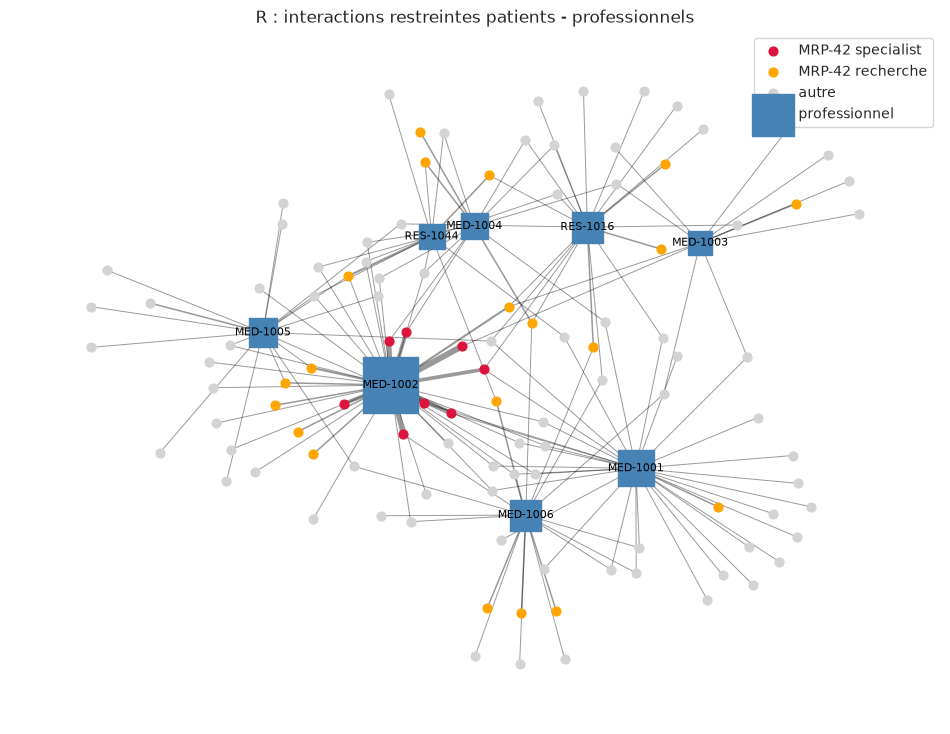

In [11]:
# Visualisation de R : couleur = groupe du patient, taille = degré pondéré
couleurs = {'MRP-42 specialist': 'crimson', 'MRP-42 recherche': 'orange', 'autre': 'lightgrey'}
pos = nx.spring_layout(R, weight='weight', seed=3, k=0.25)
plt.figure(figsize=(12, 9))
nx.draw_networkx_edges(R, pos, width=[0.3 + 0.4 * d['weight'] for _, _, d in R.edges(data=True)], alpha=.4)
for grp, col in couleurs.items():
    noeuds = [n for n in R if R.nodes[n]['kind'] == 'patient' and groupe(n) == grp]
    nx.draw_networkx_nodes(R, pos, nodelist=noeuds, node_color=col, node_size=40, label=grp)
nx.draw_networkx_nodes(R, pos, nodelist=[n for n in R if n.startswith('LIC')], node_color='steelblue', node_shape='s',
                       node_size=[40 * R.degree(n, weight='weight') ** .8 for n in R if n.startswith('LIC')], label='professionnel')
nx.draw_networkx_labels(R, pos, labels={n: n.replace('LIC-VLN-', '') for n in R if n.startswith('LIC')}, font_size=8)
plt.legend(); plt.title('R : interactions restreintes patients - professionnels'); plt.axis('off'); plt.show()

**Lecture**
- **G** : une seule composante ; Louvain trouve une communauté par professionnel (Q ≈ 0,33) : chaque patient est rattaché à « son » praticien principal. C'est l'organisation normale d'une patientèle, pas un indice.
- **R** : la structure est plus nette (Q ≈ 0,55, 7 communautés). La communauté de `LIC-VLN-MED-1002` contient **les 8 patients `MRP-42 specialist`** (et 6 sujets de recherche qu'il a aussi traités) ; les 14 autres patients `MRP-42 recherche` sont **dispersés** dans 5 autres communautés, autour d'autres praticiens. Les deux volets de `MRP-42` n'ont donc pas la même organisation : l'un est un circuit fermé autour d'un seul médecin, l'autre un protocole de recherche distribué.
- Girvan-Newman (sur R seulement) donne 6 communautés et une modularité plus faible (≈ 0,40). Il retire les liens selon leur betweenness **non pondérée** : il ignore donc l'intensité des liens, fusionne `LIC-VLN-MED-1002` et `LIC-VLN-MED-1001` (40 nœuds) et répartit les 8 patients `specialist` dans 4 communautés. Le regroupement autour de 1002 tient donc **aux poids** (6 à 10 interactions par patient), pas à la seule existence des liens. Sur G, Girvan-Newman détache d'abord des feuilles une par une : on ne l'applique pas.
- Infomap demande `cdlib` et `infomap` ; la cellule l'ignore proprement s'ils ne sont pas installés.
- Le clustering de la projection patients est élevé : c'est mécanique, tous les patients d'un même praticien forment une clique dans la projection. On ne l'interprète pas.

## 5. Process mining
**Event log** : `case_id` = patient, `activity` = type de consultation, `timestamp` = début de consultation. On construit le **DFG** (graphe orienté des successions directes A → B) à la main, puis on calcule la mesure de dépendance du **Heuristic Miner** : `dep(A,B) = (|A>B| − |B>A|) / (|A>B| + |B>A| + 1)`. `pm4py` est utilisé en complément s'il est installé (Heuristic et Inductive Miner). Le **Fuzzy Miner** n'existe pas dans `pm4py` (il est dans ProM) ; son idée (garder les liens fréquents et significatifs, agréger le reste) est approchée en filtrant le DFG.

In [12]:
log = enc[['patient_number', 'encounter_type', 'encounter_start']].rename(
    columns={'patient_number': 'case_id', 'encounter_type': 'activity', 'encounter_start': 'timestamp'}).sort_values(['case_id', 'timestamp'])
log['groupe'] = log.case_id.map(groupe)
print(log.shape[0], 'événements,', log.case_id.nunique(), 'cas,', log.activity.nunique(), 'activités')

def dfg(lg):
    s = lg.assign(suivante=lg.groupby('case_id').activity.shift(-1)).dropna(subset=['suivante'])
    return s.groupby(['activity', 'suivante']).size().rename('n').reset_index()

def dependance(d):
    m = d.set_index(['activity', 'suivante']).n
    d = d.copy()
    d['inverse'] = [m.get((b, a), 0) for a, b in zip(d.activity, d.suivante)]
    d['dependance'] = (d.n - d.inverse) / (d.n + d.inverse + 1)
    return d.sort_values('n', ascending=False)

D = dependance(dfg(log))
D.head(12)

1067 événements, 240 cas, 10 activités


,activity,suivante,n,inverse,dependance
35,specialist_follow_up,specialist_follow_up,72,72,0.000000
8,general_examination,general_examination,63,63,0.000000
16,occupational_assessment,general_examination,59,49,0.091743
19,occupational_assessment,specialist_follow_up,56,53,0.027273
13,mobility_assessment,mobility_assessment,54,54,0.000000
17,occupational_assessment,occupational_assessment,54,54,0.000000
32,specialist_follow_up,occupational_assessment,53,56,-0.027273
0,cardiac_assessment,cardiac_assessment,53,53,0.000000
11,general_examination,specialist_follow_up,50,48,0.020202
9,general_examination,occupational_assessment,49,59,-0.091743


In [13]:
# Variantes (séquence complète d'activités) par groupe de patients
variantes = log.groupby('case_id').agg(groupe=('groupe', 'first'), variante=('activity', lambda a: ' > '.join(a)))
for grp in ['MRP-42 specialist', 'MRP-42 recherche', 'autre']:
    v = variantes[variantes.groupe == grp].variante
    print(f'--- {grp} : {len(v)} patients, {v.nunique()} variantes distinctes')
    for var, n in v.value_counts().head(3).items():
        print(f'   {n} x  {var[:180]}')

--- MRP-42 specialist : 8 patients, 3 variantes distinctes
   4 x  executive_health_review > specialist_procedure > executive_health_review > specialist_procedure > executive_health_review > specialist_procedure > executive_health_review > special
   3 x  executive_health_review > specialist_procedure > executive_health_review > specialist_procedure > executive_health_review > specialist_procedure > executive_health_review
   1 x  executive_health_review > specialist_procedure > executive_health_review > specialist_procedure > executive_health_review > specialist_procedure > executive_health_review > special
--- MRP-42 recherche : 20 patients, 19 variantes distinctes
   2 x  occupational_assessment > specialist_follow_up > specialist_follow_up > research_procedure
   1 x  cardiac_assessment > cardiac_assessment > cardiac_assessment > research_procedure > cardiac_assessment > cardiac_assessment
   1 x  executive_health_review > executive_health_review > executive_health_review > executi

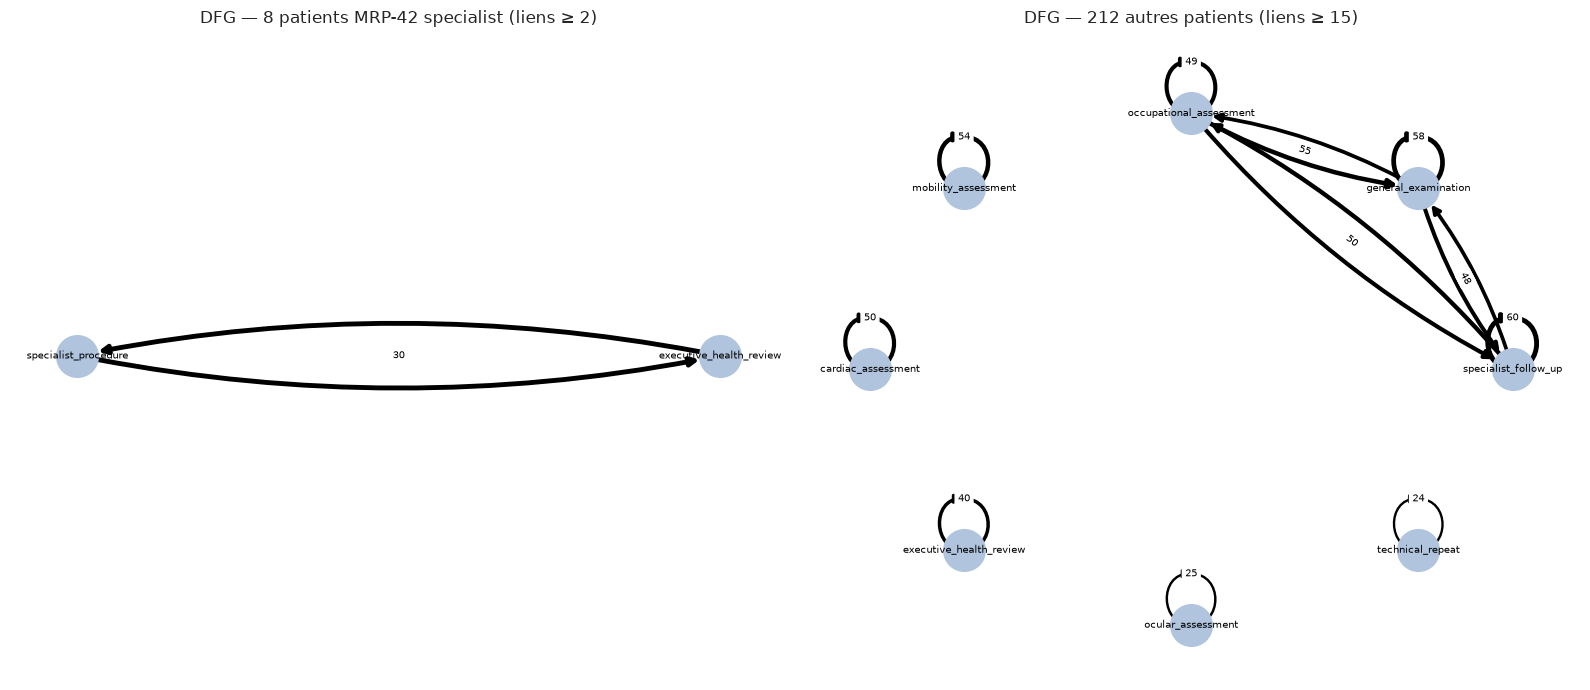

In [14]:
# DFG filtré (idée du Fuzzy Miner : on ne garde que les liens fréquents) pour les patients MRP-42 specialist vs les autres
def dessiner_dfg(lg, titre, seuil):
    d = dependance(dfg(lg)); d = d[d.n >= seuil]
    g = nx.DiGraph()
    g.add_weighted_edges_from(d[['activity', 'suivante', 'n']].itertuples(index=False))
    pos = nx.circular_layout(g)
    nx.draw_networkx(g, pos, node_color='lightsteelblue', node_size=900, font_size=7, arrowsize=12,
                     width=[0.5 + 3 * w / d.n.max() for _, _, w in g.edges(data='weight')], connectionstyle='arc3,rad=0.1')
    nx.draw_networkx_edge_labels(g, pos, edge_labels={(u, v): w for u, v, w in g.edges(data='weight')}, font_size=7)
    plt.title(titre); plt.axis('off')

plt.figure(figsize=(16, 7))
plt.subplot(1, 2, 1); dessiner_dfg(log[log.groupe == 'MRP-42 specialist'], 'DFG — 8 patients MRP-42 specialist (liens ≥ 2)', 2)
plt.subplot(1, 2, 2); dessiner_dfg(log[log.groupe == 'autre'], 'DFG — 212 autres patients (liens ≥ 15)', 15)
plt.tight_layout(); plt.show()

**Lecture**
- Le processus global est **peu structuré** : 212 patients « autres » ont 120 variantes, les variantes les plus fréquentes répètent un seul type (5 `mobility_assessment` de suite, etc.), et les successions entre types différents sont **symétriques** (A → B aussi fréquent que B → A, dépendance proche de 0). C'est un modèle « spaghetti », typique d'un suivi au long cours.
- Les **8 patients `MRP-42 specialist`** ont au contraire un parcours **identique** (3 variantes seulement, qui ne diffèrent que par le nombre de répétitions) : `executive_health_review` → `specialist_procedure`, en boucle, sur plusieurs années. Le DFG de ce groupe se réduit à ce cycle.
- Les 20 patients `MRP-42 recherche` ont 19 variantes : un parcours ordinaire **avec une seule** `research_procedure` insérée, souvent en fin de séquence. Un passage unique, pas un cycle.
- Conclusion : le process mining confirme que `MRP-42` recouvre **deux processus différents** : un traitement récurrent pour 8 personnes, une administration ponctuelle pour 20 sujets de recherche.

## 6. À retenir pour le bloc 7
| Observation | Méthode | Hypothèse |
|---|---|---|
| `LIC-VLN-MED-1002` central uniquement dans le sous-graphe restreint ; liens les plus lourds vers les 8 patients `MRP-42 specialist` | Centralités sur R, liens pondérés | Un praticien unique gère un circuit réservé (Dr. Naima Orrel d'après `public_records`) |
| Communauté Louvain de `LIC-VLN-MED-1002` contenant les 8 patients `specialist` dans R (Q ≈ 0,55) ; patients « recherche » dispersés | Louvain, Girvan-Newman, modularité | `MRP-42` = programme fermé pour une élite + essai distribué |
| Cycle `executive_health_review` → `specialist_procedure` répété chez les 8 | DFG, mesure de dépendance, variantes | Administration périodique (intervalle étudié au bloc 5) |
| Pas de loi de puissance, P complet | CCDF log-log, densité | Pas d'indice : structure attendue d'une patientèle |